<a href="https://colab.research.google.com/github/loudamn78-gif/smartstay-ai/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. فهم المشكلة

**١. من العميل؟ وما مشكلته؟ وكم تكلّفه؟**
العميل هو مالك جديد على منصة تأجير شقق قصيرة في نيويورك. المنصة فيها قرابة 49 ألف إعلان (48,895 في الداتا)، وسعر الليلة فيها من 10 إلى 10,000 دولار. مشكلته أنه يسعّر شقته بالتخمين: لو غلّى السعر ما يحجز عنده أحد، ولو رخّصه يخسر من دخله في كل ليلة.

**٢. ما الـ Target؟ وما نوعه؟**
الـ Target هو `price` (سعر الليلة بالدولار). نوعه **رقم** (يظهر في `dtypes` كـ int64)، مثل 149 و225 و80 في أول صفوف الداتا. ولأنه رقم، فالمشكلة هي توقّع رقم وليست تصنيفًا.

**٣. من سيستخدم منتجك؟ وماذا يحتاج أن يرى أول ما يفتحه؟**
سيستخدمه المالك الجديد. أول ما يفتح الأداة يدخل منطقة الشقة ونوع الغرفة، ويحتاج يرى مباشرة السعر المقترح لليلة الواحدة، مع شقق مشابهة لشقته وأسعارها، حتى يقرر بناءً على بيانات وليس تخمينًا.

**٤. ثلاثة أسئلة فرعية ستساعدني في الإجابة عن سؤال العميل:**
1. كيف يختلف سعر الليلة بين المناطق (`neighbourhood_group`)؟
2. كيف يختلف السعر بين أنواع الغرف (`room_type`)؟
3. هل للحد الأدنى لعدد الليالي (`minimum_nights`) أو عدد أيام التوفر خلال السنة (`availability_365`) علاقة بالسعر؟

##2. اول نظرة

## الاستيراد وقراءة الداتا

In [79]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", None)
df = pd.read_csv("data/raw.csv")

In [80]:
print("الصفوف والأعمدة:", df.shape)

الصفوف والأعمدة: (48895, 16)


## **:عينة**

In [81]:
display(df.head())

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


## الانواع:

In [82]:
display(df.dtypes)

,0
id,int64
name,object
host_id,int64
host_name,object
neighbourhood_group,object
neighbourhood,object
latitude,float64
longitude,float64
room_type,object
price,int64


## النقص:

In [83]:
display(df.isna().sum().sort_values(ascending=False))

,0
last_review,10052
reviews_per_month,10052
host_name,21
name,16
neighbourhood_group,0
neighbourhood,0
id,0
host_id,0
longitude,0
latitude,0


## التكرار:

In [84]:
print("الصفوف المكررة:", df.duplicated().sum())
print("id مكرر:", df["id"].duplicated().sum())

الصفوف المكررة: 0
id مكرر: 0


## الاحصائيات:

In [85]:
display(df.describe())

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


## القيم الفريدة في الاعمدة النصية:

In [86]:
for col in df.select_dtypes(include="object").columns:
    print(f"{col}: {df[col].nunique()} قيمة فريدة -> {list(df[col].dropna().unique()[:5])}")

name: 47905 قيمة فريدة -> ['Clean & quiet apt home by the park', 'Skylit Midtown Castle', 'THE VILLAGE OF HARLEM....NEW YORK !', 'Cozy Entire Floor of Brownstone', 'Entire Apt: Spacious Studio/Loft by central park']
host_name: 11452 قيمة فريدة -> ['John', 'Jennifer', 'Elisabeth', 'LisaRoxanne', 'Laura']
neighbourhood_group: 5 قيمة فريدة -> ['Brooklyn', 'Manhattan', 'Queens', 'Staten Island', 'Bronx']
neighbourhood: 221 قيمة فريدة -> ['Kensington', 'Midtown', 'Harlem', 'Clinton Hill', 'East Harlem']
room_type: 3 قيمة فريدة -> ['Private room', 'Entire home/apt', 'Shared room']
last_review: 1764 قيمة فريدة -> ['2018-10-19', '2019-05-21', '2019-07-05', '2018-11-19', '2019-06-22']


**ملاحظاتي من أول نظرة:**
- **الحجم:** 48,895 صف و16 عمود، وما فيه صفوف مكررة ولا `id` مكرر (0).
- **الأنواع:** معظم الأعمدة صحيحة (أرقام للأرقام ونصوص للنصوص)، لكن `last_review` مخزّن كنص (object) وليس تاريخًا، وشكله `dd-mm-yyyy`.
- **النقص:** `last_review` و`reviews_per_month` ناقصان في 10,052 صف لكل منهما (نفس العدد)، و`host_name` ناقص في 21 صف، و`name` في 16 صف.
- **الـ Target (`price`):** أقل قيمة 0، ووسيطه 106 دولار، ومتوسطه 152.7، وأعلى قيمة 10,000. المتوسط أكبر من الوسيط، فالأسعار العالية جدًا تسحبه للأعلى.
- **`minimum_nights`:** وسيطه 3 ليالٍ، لكن أعلى قيمة 1,250 ليلة (أكثر من 3 سنوات).
- **الأعمدة النصية:** 5 مناطق (`neighbourhood_group`)، و221 حيًّا، و3 أنواع غرف.
- **الإحداثيات:** كلها ضمن نطاق نيويورك.

## 3.EDA

### الرسمة 1: توزيع الـ Target (price)

count    48895.0
mean       152.7
std        240.2
min          0.0
25%         69.0
50%        106.0
75%        175.0
max      10000.0
Name: price, dtype: float64
99%: 799.0


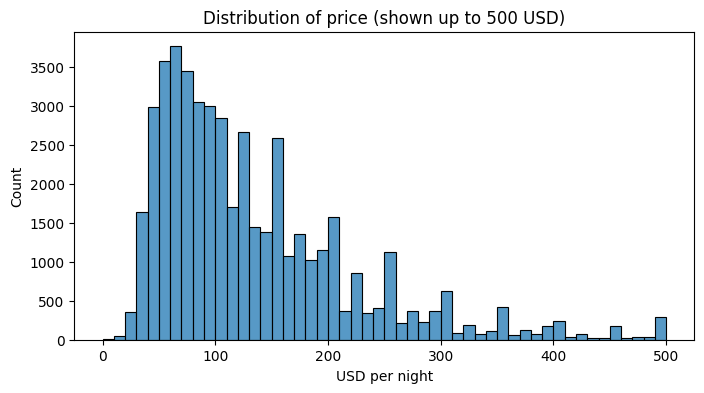

In [87]:
print(df["price"].describe().round(1))
print("99%:", df["price"].quantile(0.99))

# للعرض فقط: نقص الرسم عند 500 دولار حتى يظهر الشكل (لا نعدّل df)
plt.figure(figsize=(8, 4))
sns.histplot(df.loc[df["price"] <= 500, "price"], bins=50)
plt.title("Distribution of price (shown up to 500 USD)")
plt.xlabel("USD per night")
plt.show()

**الجملة:** وسيط سعر الليلة 106 دولار بينما المتوسط 152.7، لأن قلّة من الإعلانات غالية جدًا (أعلى سعر 10,000 دولار، و99% من الإعلانات أقل من 799 دولار) تسحب المتوسط للأعلى، وأغلب الأسعار تتركز بين 50 و150 دولار تقريبًا.

### الرسمة 2: السعر حسب المنطقة

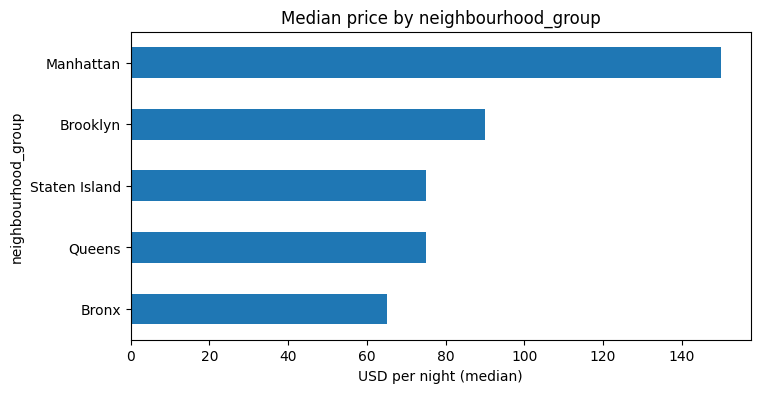

neighbourhood_group
Bronx             65.0
Queens            75.0
Staten Island     75.0
Brooklyn          90.0
Manhattan        150.0
Name: price, dtype: float64


In [88]:
med_area = df.groupby("neighbourhood_group")["price"].median().sort_values()
med_area.plot(kind="barh", figsize=(8, 4), title="Median price by neighbourhood_group")
plt.xlabel("USD per night (median)")
plt.show()
print(med_area)

**الجملة:** Manhattan الأغلى بوسيط 150 دولار لليلة، وBronx الأرخص بـ65 دولار، أي فرق 85 دولار (أكثر من الضعف)، وBrooklyn في الوسط بـ90 دولار، وQueens وStaten Island متساويتان عند 75 دولار.

### الرسمة 3: السعر حسب نوع الغرفة

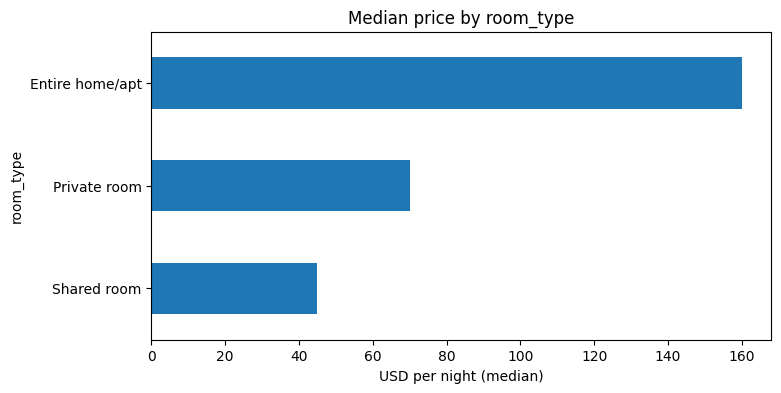

room_type
Shared room         45.0
Private room        70.0
Entire home/apt    160.0
Name: price, dtype: float64


In [89]:
med_room = df.groupby("room_type")["price"].median().sort_values()
med_room.plot(kind="barh", figsize=(8, 4), title="Median price by room_type")
plt.xlabel("USD per night (median)")
plt.show()
print(med_room)

**أهم عمودين في رأيي وعلاقتهما بالـ Target:**
1. `room_type`: لأن وسيط السعر يتغير من 45 دولار (غرفة مشتركة) إلى 160 دولار (شقة كاملة)، أي أكثر من 3 أضعاف.
2. `neighbourhood_group`: لأن وسيط السعر يتغير من 65 دولار في Bronx إلى 150 دولار في Manhattan، أي أكثر من الضعف.

## 4. مفاجآت الداتا

##1. النقص:

In [90]:
miss = df.isna().sum()
print(miss[miss > 0])
print("last_review و reviews_per_month ناقصان معًا:", int((df["last_review"].isna() & df["reviews_per_month"].isna()).sum()))
print("صفر تقييمات number_of_reviews == 0:", int((df["number_of_reviews"] == 0).sum()))

name                    16
host_name               21
last_review          10052
reviews_per_month    10052
dtype: int64
last_review و reviews_per_month ناقصان معًا: 10052
صفر تقييمات number_of_reviews == 0: 10052


## 2.ال Target:

In [91]:
print("price == 0:", int((df["price"] == 0).sum()))
print("price > 1000:", int((df["price"] > 1000).sum()), "| max:", df["price"].max())
print(df.loc[df["price"] >= 5000, ["name", "neighbourhood_group", "room_type", "price"]].head(10))

price == 0: 11
price > 1000: 239 | max: 10000
                                      name neighbourhood_group  \
2698   Beautiful 1 Bedroom in Nolita/Soho            Manhattan   
3537    UWS 1BR w/backyard + block from CP           Manhattan   
3720   SuperBowl Penthouse Loft 3,000 sqft           Manhattan   
3774      SUPER BOWL Brooklyn Duplex Apt!!            Brooklyn   
4345      NearWilliamsburg bridge 11211 BK            Brooklyn   
4377                         Film Location            Brooklyn   
6530                    Spanish Harlem Apt           Manhattan   
9151   Furnished room in Astoria apartment              Queens   
12342  Quiet, Clean, Lit @ LES & Chinatown           Manhattan   
15560   Luxury townhouse Greenwich Village           Manhattan   

             room_type  price  
2698   Entire home/apt   5000  
3537   Entire home/apt   6000  
3720   Entire home/apt   5250  
3774   Entire home/apt   6500  
4345      Private room   5000  
4377   Entire home/apt   8000  
653

## 3. الحد الادنى لليالي:

In [92]:
print("minimum_nights > 30:", int((df["minimum_nights"] > 30).sum()))
print("minimum_nights > 365:", int((df["minimum_nights"] > 365).sum()), "| max:", df["minimum_nights"].max())

minimum_nights > 30: 747
minimum_nights > 365: 14 | max: 1250


##4.التوفر:

In [93]:
print("availability_365 == 0:", int((df["availability_365"] == 0).sum()))

availability_365 == 0: 17533


##5.نوع التاريخ:

In [94]:
print(df["last_review"].dtype, "| مثال:", df["last_review"].dropna().iloc[0])

object | مثال: 2018-10-19


##6. الاحداثيات:

In [95]:
out = ~df["latitude"].between(40.4, 41.0) | ~df["longitude"].between(-74.3, -73.7)
print("خارج نطاق نيويورك:", int(out.sum()))

خارج نطاق نيويورك: 0


##7.الفئات:

In [96]:
print(df["neighbourhood_group"].value_counts(dropna=False).to_dict())
print(df["room_type"].value_counts(dropna=False).to_dict())
print("neighbourhood فريد:", df["neighbourhood"].nunique())

{'Manhattan': 21661, 'Brooklyn': 20104, 'Queens': 5666, 'Bronx': 1091, 'Staten Island': 373}
{'Entire home/apt': 25409, 'Private room': 22326, 'Shared room': 1160}
neighbourhood فريد: 221


### جدول المفاجآت

| المشكلة | العمود | كم صفًا؟ | قراري المبدئي |
|---|---|---|---|
| سعر الليلة صفر (قيمة مستحيلة) | `price` | 11 | أستبعدها قبل بناء الأداة، لأن شقة بسعر 0 غير منطقية |
| أسعار متطرفة جدًا (أكثر من 1000 دولار، وأعلى سعر 10,000) | `price` | 239 | أراجعها غدًا: بعضها يبدو غير واقعي (غرفة خاصة بـ10,000 دولار)، فأغلب الظن أستبعدها أو أحدّ منها |
| حد أدنى للإقامة أكثر من سنة (أعلى قيمة 1,250 ليلة) | `minimum_nights` | 14 | أستبعدها، لأنها لا تناسب التأجير القصير |
| حد أدنى أكثر من 30 ليلة (إيجار شهري وليس قصيرًا) | `minimum_nights` | 747 | أقرر غدًا هل أبقيها أو أستبعدها، حسب تأثيرها على السعر |
| نقص في تاريخ آخر تقييم ومتوسط التقييمات الشهري | `last_review` و`reviews_per_month` | 10,052 لكل منهما | ليس خطأ: نفس عدد الإعلانات بصفر تقييمات (10,052)، فأتركه فارغًا لـ`last_review` وأعوّض `reviews_per_month` بصفر |
| تاريخ مخزّن كنص بدل تاريخ | `last_review` | 38,843 (غير الناقصة) | أحوّله إلى تاريخ بصيغة يوم-شهر-سنة |
| غير متاح طوال السنة (availability = 0) | `availability_365` | 17,533 | أبقيها لكن أراجع علاقتها بالسعر، لأن قد تكون إعلانات موقوفة |
| اسم الإعلان أو المضيف ناقص | `name` و`host_name` | 16 و21 | لا أحتاجهما في تسعير الشقة، فأتجاهلهما |
**فحوصات أخرى طلعت سليمة:**
- **الإحداثيات (`latitude` و`longitude`):** كلها داخل نطاق نيويورك (0 خارج النطاق).
- **الفئات:** `neighbourhood_group` فيها 5 مناطق و`room_type` فيها 3 أنواع فقط بدون أخطاء كتابة أو قيم غريبة، و`neighbourhood` فيها 221 قيمة فريدة.
- **التكرار:** 0 صفوف مكررة و0 `id` مكرر.